# Lab Report: Interpolation
## Algorithm to implement the lagrange interpolation

In [2]:
from google.colab import files

ModuleNotFoundError: No module named 'google.colab'


### Choose a cambered airfoil NACA-abcd. For given number of points on the airfoil geometry (N), reconstruct smooth airfoil surface.
### ▶ Use random number generator in numpy to choose each the maximum camber, the location of maximum camber and the the percentage of thickness to chord.
### ▶ Use the function ’Lagrng()’ that you wrote to reconstruct the airfoil.
### ▶ Plot the original airfoil and the reconstructed one.
### ▶ Quantify the error (max, RMS) between the true and reconstructed results.
### ▶ Document your work on ’how can you improve your results by choosing spacing between data points?’
### ▶ Reconstruct the airfoil using cubic splines and quantify the errors. This requires writing a python function for cubic spline interpolation


**Lagrange Interpolation**

Given N data points, Lagrange interpolation constructs a single polynomial 
of degree N-1 that passes through all of them:
$$
P(x)=\sum_{i=0}^n y(i)Li(x)
$$
$$
Li(x)=\prod_{j=0}^n \frac{(xx-xj)}{(xi-xj)}
$$


**Overall approach:**
- A NACA 4-digit airfoil is generated with randomly chosen camber (m), 
  camber location (p), and thickness (t), using `numpy.random.uniform`.
- A dense set of 500 points is generated as the "true" reference airfoil.
- A sparse set of N points (N=12) is sampled from the same 
  airfoil.
- Both Lagrange interpolation and cubic spline interpolation are used to 
  reconstruct the full airfoil shape from only the sparse points.
- The reconstructed curves are compared against the dense "true" curve, 
  and error is quantified using maximum absolute error and RMS error.


### First writing code for sum of numbers as an example

In [3]:
import numpy as np
def lagrng(x, y):
    sum=0
    for i in range(0,6):
        sum=sum+x[i]
    print(sum)

x=np.array([0,1,2,3,4,5])
y=x
lagrng(x,y)

15


### Now writing code for finding the number(coordinate) between the given cordinates

In [4]:
## Example
import numpy as np
def lagrng(x,y,n,xx):
    sum=0
    for i in range (0,n):
        product=y[i]
        for j in range(0,n):
            if i!=j:
                product=product*((xx - x[j])/(x[i] - x[j]))
        sum=sum+product
    return sum

x=np.array([0,1,2,3,4,5])
y=np.array([1,3,5,7,9,11])
lagrng(x,y,5,2.5)

np.float64(6.0)

### Now writing the same code for sin(x)

In [5]:
import numpy as np
def lagrng(x,y,n,xx):
    sum=0
    for i in range (0,n):
        product=y[i]
        for j in range(0,n):
            if i!=j:
                product=product*((xx - x[j])/(x[i] - x[j]))
        sum=sum+product
    return sum

x=np.array([0,np.pi/6, np.pi/4, np.pi/3, np.pi/2, np.pi])
y=np.sin(x)
lagrng(x,y,len(x),np.pi)

np.float64(1.2246467991473532e-16)

### Comparing the algorithm with the lagrange function
#### now here for same value of x=pi/6 both gives the same value of 0.4999... upto 14 decimal places

In [6]:
result1=lagrng(x, y, len(x), np.pi/6)
print(result1)
np.sin(np.pi/6)

0.49999999999999994


np.float64(0.49999999999999994)

#### Now trying to create a random value selection for (m= maximum camber), (p= camber location) and (t= maximum thickness)

In [7]:
np.random.seed(1)                             ## fixes the random draw so m, p, t (and all errors) are the same on every run
m=np.random.uniform(0.01, 0.06)               ## realistic range of maximum camber for cambered airfoil
print("maximum camber(m):", m)

p=np.random.uniform(0.15, 0.60)               ## realistic range of camber location for cambered airfoil
print("camber location(p):", p)

t=np.random.uniform(0.06, 0.18)               ## realistic range of maximum thickness for cambered airfoil
print("maximum thickness(t):", t)

maximum camber(m): 0.0308511002351287
camber location(p): 0.47414602204897116
maximum thickness(t): 0.060013724978081384


# Now defing the NACA 4 digit Airfoil for point generation

In [8]:
import matplotlib.pyplot as plt
def naca_4digit(m,p,t,n=200, x=None):
    if x is None:
        x=np.linspace(0,1,n)

    yt= 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)  #thickness distribution
    yc=np.where( x<p, 
             m/p**2 * (2*p*x - x**2),
             m/(1-p)**2 * ((1-2*p) + 2*p*x - x**2))
    yu=yc + yt
    yl=yc - yt
    return x,yu,yl,yc

In [9]:
xtrue, yutrue, yltrue, yctrue = naca_4digit(m, p, t, n=500)          ## for actual true curve
x, yu, yl, yc= naca_4digit(m, p, t, n=12)                            ## for sparse points on curve

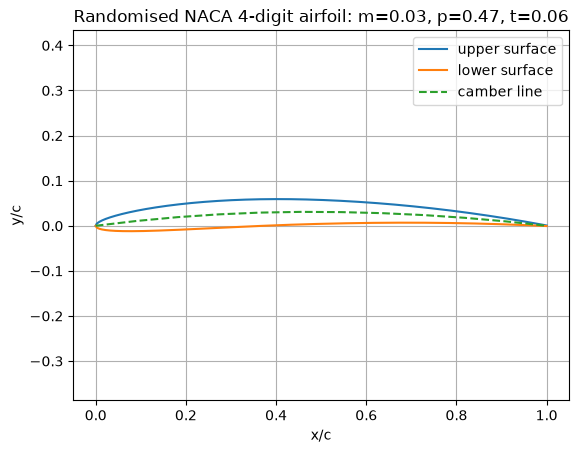

In [10]:
plt.plot(xtrue,yutrue, label="upper surface")
plt.plot(xtrue,yltrue, label="lower surface")
plt.plot(x,yc,'--', label="camber line")
plt.legend()
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.axis("equal")
plt.title(f"Randomised NACA 4-digit airfoil: m={m:.2f}, p={p:.2f}, t={t:.2f}")      ## f here tells to look inside the string and replace them with actual variable and , :.2f also spectifies the no. of decimal places to shoe
plt.grid(True)
plt.show()

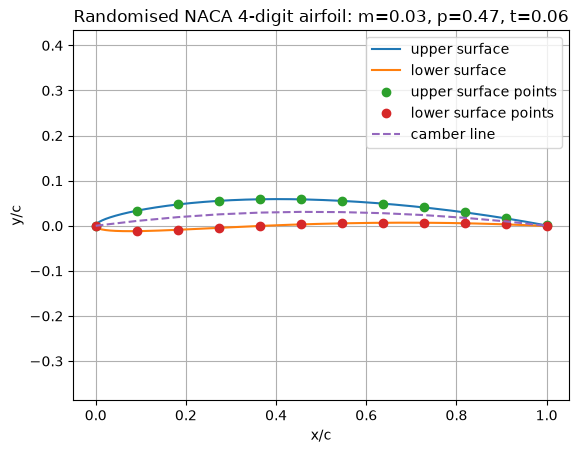

In [11]:
plt.plot(xtrue,yutrue, label="upper surface")
plt.plot(xtrue,yltrue, label="lower surface")
plt.plot(x,yu, 'o', label="upper surface points")
plt.plot(x,yl, 'o', label="lower surface points")
plt.plot(x,yc,'--', label="camber line")
plt.legend()
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.axis("equal")
plt.title(f"Randomised NACA 4-digit airfoil: m={m:.2f}, p={p:.2f}, t={t:.2f}")      ## f here tells to look inside the string and replace them with actual variable and , :.2f also spectifies the no. of decimal places to shoe
plt.grid(True)
plt.show()

## Example

In [12]:
numbers=[1,2,3,4,5]
squares=[]

for n in numbers :
    result = n**2
    squares.append(result)
print(squares)

[1, 4, 9, 16, 25]


## Now storing the output

In [13]:
y_new_upper = []
for xx in xtrue:                                      ## xx takes each value from xtrue
    result=(lagrng(x, yu, len(x), xx))                ## compute 1 new y value at this xx
    y_new_upper.append(result)                        ## store that y value in the list

y_new_lower = []
for xx in xtrue:                                      ## xx takes each value from xtrue
    result=(lagrng(x, yl, len(x), xx))                ## compute 1 new y value at this xx
    y_new_lower.append(result)                        ## store that y value in the list

In [14]:
print(y_new_upper [0])
print(y_new_lower [0])
print(yutrue [0])

0.0
0.0
0.0


In [15]:
mid = len(xtrue) // 2                 ## checking the value of y_new_upper nad yutrue and the midpoint
print(y_new_upper[mid])
print(yutrue[mid])
print(y_new_lower[mid])
print(yltrue[mid])

0.05722765032206476
0.05721513256000326
0.004336505516821568
0.004326132208436258


# Now generating all 3 graphs in one, that is with actual curve,  the sparse points and the new generated points 

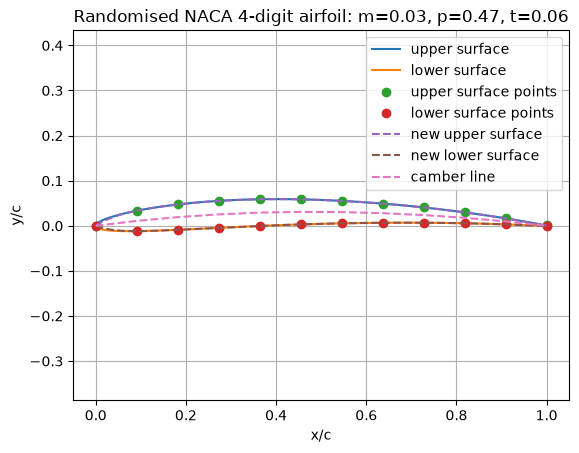

In [16]:
plt.plot(xtrue,yutrue, label="upper surface")
plt.plot(xtrue,yltrue, label="lower surface")
plt.plot(x,yu, 'o', label="upper surface points")
plt.plot(x,yl, 'o', label="lower surface points")
plt.plot(xtrue,y_new_upper, '--', label="new upper surface")
plt.plot(xtrue,y_new_lower, '--', label="new lower surface")
plt.plot(x,yc,'--', label="camber line")
plt.legend()
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.axis("equal")
plt.title(f"Randomised NACA 4-digit airfoil: m={m:.2f}, p={p:.2f}, t={t:.2f}")      ## f here tells to look inside the string and replace them with actual variable and , :.2f also spectifies the no. of decimal places to shoe
plt.grid(True)
plt.show()

# Now calculating error
#### Now as we have y_new_upper and y_new_lower in the list and yutrur , yltrue in the numpy.ndarray format, we cant directly subtract it to find the error


In [17]:
type(yutrue)

numpy.ndarray

In [18]:
type(y_new_upper)

list

In [19]:
y_new_upper=np.array(y_new_upper)           ## converting list into numpy array
y_new_lower=np.array(y_new_lower)

In [20]:
error_upper = yutrue - y_new_upper
          
error_lower = yltrue - y_new_lower


max_error_upper=np.max(abs(error_upper))         ## getting the absolute value as there can be both positive and negative value of error
print(f"max_error_upper={max_error_upper}")

max_error_lower=np.max(abs(error_lower))
print(f"max_error_lower={max_error_lower}")

max_error_upper=0.0036247145366540704
max_error_lower=0.0038611544102510904


### now to calculate error using RMS
$$
RMS=\sqrt \frac{1}{n} \sum_{i=1}^n error_i^2
$$

In [21]:
rms_error_upper=np.sqrt(np.mean(error_upper**2))
print(f"RMS_error_upper={rms_error_upper}")
rms_error_lower=np.sqrt(np.mean(error_lower**2))
print(f"RMS_error_lower={rms_error_lower}")

RMS_error_upper=0.0005700055612099536
RMS_error_lower=0.0006361148575336849


# How can you improve your results by choosing spacing between data points?
### As in this report we have selected n=12 , so there are 12 sparse points evenly spread out over the upper curve as well as lower curve.
### But the curve is too steep near the leading edge and flat near the trailing edge, so it does not take this into consideration.

#### Thatswhy using cosine spaceing to generate more points near leading edge so it can capture the steepness of the airfoil.

In [22]:
theta = np.linspace(0, np.pi, 12)
x_cos = (1 - np.cos(theta)) / 2

x_cos, yu_cos, yl_cos, yc_cos = naca_4digit(m, p, t, x=x_cos)
print(x_cos)

[0.         0.02025351 0.07937323 0.17256963 0.29229249 0.42884258
 0.57115742 0.70770751 0.82743037 0.92062677 0.97974649 1.        ]


### So here as we can see the points have small gaps near the leading edge , large gap in middle and again small gaps near trailing edge.

In [23]:
## now creating new lagrange for the cos spacing
y_new_upper_cos = []
for xx in xtrue:                                  
    result=(lagrng(x_cos, yu_cos, len(x_cos), xx))                
    y_new_upper_cos.append(result)   
y_new_upper_cos=np.array(y_new_upper_cos)

y_new_lower_cos = []
for xx in xtrue:                                    
    result=(lagrng(x_cos, yl_cos, len(x_cos), xx))                
    y_new_lower_cos.append(result)                        
y_new_lower_cos=np.array(y_new_lower_cos)

In [24]:
## now calculating error using cosine spacing
error_upper_cos= yutrue - y_new_upper_cos
error_lower_cos= yltrue - y_new_lower_cos

max_error_upper_cos=np.max(np.abs(error_upper_cos))
max_error_lower_cos=np.max(np.abs(error_lower_cos))

rms_error_upper_cos=np.sqrt(np.mean(error_upper_cos**2))
rms_error_lower_cos=np.sqrt(np.mean(error_lower_cos**2))

print(f"Max_error_upper_cos={max_error_upper_cos}")
print(f"Max_error_lower_cos={max_error_lower_cos}")
print(f"RMS_error_upper_cos={rms_error_upper_cos}")
print(f"RMS_error_lower_cos={rms_error_lower_cos}")

Max_error_upper_cos=0.002393141598615574
Max_error_lower_cos=0.00239420366792107
RMS_error_upper_cos=0.00038680384989140906
RMS_error_lower_cos=0.0003856881248241235


### Reconstructing the same n=12 points with cosine spacing reduced the maximum error on the both surface ,error also improved slightly.
### So by this we can say that the location of interpolation points matter, which can significantly affect the accuracy of the curve, particularly in the region of high curvature such as leading edge.

### References
1. NACA airfoil equations: https://en.wikipedia.org/wiki/NACA_airfoil
2. Lagrange polynomial: https://en.wikipedia.org/wiki/Lagrange_polynomial


# Cubic Spline

## Cubic Spline Interpolation

**Cubic Spline Interpolation**

Rather than fitting one high-degree polynomial through all points, a cubic 
spline fits a separate cubic polynomial between each pair of adjacent 
points, with continuity of value, first derivative, and second derivative 
enforced at every interior point 

The cubic spline piece between $x_i$ and $x_{i+1}$ is given by:

$$S_i(x) = \frac{M_i}{6h_i}(x_{i+1}-x)^3 + \frac{M_{i+1}}{6h_i}(x-x_i)^3 + \left(\frac{y_i}{h_i} - \frac{M_i h_i}{6}\right)(x_{i+1}-x) + \left(\frac{y_{i+1}}{h_i} - \frac{M_{i+1} h_i}{6}\right)(x-x_i)$$


The unknown $M_i$ values are found by enforcing smooth (matching curvature) connections between adjacent pieces at every interior point, which leads to the following system of equations:

$$h_{i-1} M_{i-1} + 2(h_{i-1}+h_i) M_i + h_i M_{i+1} = 6\left(\frac{y_{i+1}-y_i}{h_i} - \frac{y_i - y_{i-1}}{h_{i-1}}\right)$$

For a **natural cubic spline**, curvature is set to zero at the endpoints:

$$M_0 = 0, \qquad M_{n} = 0$$

In [25]:
import numpy as np
import matplotlib.pyplot as plt

def cubic_spline_M(x, y):
    n = len(x)
    h = np.diff(x)

    A = np.zeros((n-2, n-2))
    b = np.zeros(n-2)

    for i in range(1, n-1):
        row = i - 1
        if i-1 >= 1:
            A[row, i-2] = h[i-1]
        A[row, row] = 2*(h[i-1] + h[i])
        if i+1 <= n-2:
            A[row, i] = h[i]
        b[row] = 6*((y[i+1]-y[i])/h[i] - (y[i]-y[i-1])/h[i-1])

    M_interior = np.linalg.solve(A, b)

    M = np.zeros(n)
    M[0] = 0
    M[-1] = 0
    M[1:n-1] = M_interior
    return M

In [26]:
def spline_eval(x, y, M, xx):
    n = len(x)
    i = 0
    for k in range(n-1):
        if x[k] <= xx <= x[k+1]:
            i = k
            break

    hi = x[i+1] - x[i]
    term1 = M[i]/(6*hi) * (x[i+1]-xx)**3
    term2 = M[i+1]/(6*hi) * (xx-x[i])**3
    term3 = (y[i]/hi - M[i]*hi/6) * (x[i+1]-xx)
    term4 = (y[i+1]/hi - M[i+1]*hi/6) * (xx-x[i])
    return term1 + term2 + term3 + term4

In [27]:
xtrue, yutrue, yltrue, yctrue = naca_4digit(m, p, t, n=500)
x, yu, yl, yc = naca_4digit(m, p, t, n=12)


M_upper = cubic_spline_M(x, yu)
M_lower = cubic_spline_M(x, yl)

In [28]:
y_spline_upper = []
for xx in xtrue:
    y_spline_upper.append(spline_eval(x, yu, M_upper, xx))
y_spline_upper = np.array(y_spline_upper)

y_spline_lower = []
for xx in xtrue:
    y_spline_lower.append(spline_eval(x, yl, M_lower, xx))
y_spline_lower = np.array(y_spline_lower)

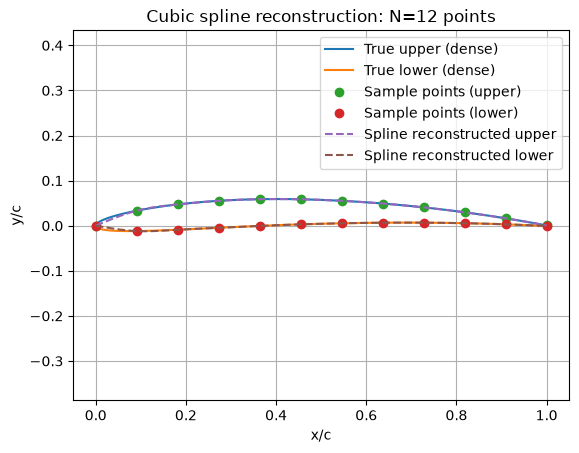

In [29]:
plt.plot(xtrue, yutrue, label="True upper (dense)")
plt.plot(xtrue, yltrue, label="True lower (dense)")
plt.plot(x, yu, 'o', label="Sample points (upper)")
plt.plot(x, yl, 'o', label="Sample points (lower)")
plt.plot(xtrue, y_spline_upper, '--', label="Spline reconstructed upper")
plt.plot(xtrue, y_spline_lower, '--', label="Spline reconstructed lower")
plt.axis("equal")
plt.legend()
plt.grid(True)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"Cubic spline reconstruction: N={len(x)} points")
plt.show()

In [30]:
error_upper_spline = yutrue - y_spline_upper
error_lower_spline = yltrue - y_spline_lower

max_error_upper_spline = np.max(np.abs(error_upper_spline))
rms_error_upper_spline = np.sqrt(np.mean(error_upper_spline**2))
max_error_lower_spline = np.max(np.abs(error_lower_spline))
rms_error_lower_spline = np.sqrt(np.mean(error_lower_spline**2))

print(f"Spline — Max error (upper): {max_error_upper_spline}")
print(f"Spline — RMS error (upper): {rms_error_upper_spline}")
print(f"Spline — Max error (lower): {max_error_lower_spline}")
print(f"Spline — RMS error (lower): {rms_error_lower_spline}")

Spline — Max error (upper): 0.00602030500510135
Spline — RMS error (upper): 0.0012474115721004602
Spline — Max error (lower): 0.005842261210115086
Spline — RMS error (lower): 0.0012014482692331119


In [31]:
from scipy.interpolate import CubicSpline

cs = CubicSpline(x, yu, bc_type='natural')
print("difference from SciPy:", np.max(np.abs(cs(xtrue) - y_spline_upper)))

difference from SciPy: 1.3877787807814457e-17


In [32]:
print("worst point at x =", xtrue[np.argmax(np.abs(error_upper_spline))])

worst point at x = 0.018036072144288574


In [33]:
# spline with cosine-spaced points
M_upper_cos = cubic_spline_M(x_cos, yu_cos)
M_lower_cos = cubic_spline_M(x_cos, yl_cos)

y_spline_upper_cos = np.array([spline_eval(x_cos, yu_cos, M_upper_cos, xx) for xx in xtrue])
y_spline_lower_cos = np.array([spline_eval(x_cos, yl_cos, M_lower_cos, xx) for xx in xtrue])

error_su_cos = yutrue - y_spline_upper_cos
error_sl_cos = yltrue - y_spline_lower_cos

print(f"Spline cos Max error (upper): {np.max(np.abs(error_su_cos))}")
print(f"Spline cos Max error (lower): {np.max(np.abs(error_sl_cos))}")
print(f"Spline cos RMS error (upper): {np.sqrt(np.mean(error_su_cos**2))}")
print(f"Spline cos RMS error (lower): {np.sqrt(np.mean(error_sl_cos**2))}")
print("worst point at x =", xtrue[np.argmax(np.abs(error_su_cos))])

Spline cos Max error (upper): 0.0029265374172024817
Spline cos Max error (lower): 0.0029167889380127105
Spline cos RMS error (upper): 0.000558533238666542
Spline cos RMS error (lower): 0.0005550470131325692
worst point at x = 0.004008016032064128


### Cubic spline vs Lagrange (N = 12)  
Airfoil parameters (np.random.seed(1)): m = 0.0309, p = 0.4741, t = 0.0600

| Method | Max err (upper) | Max err (lower) | RMS (upper) | RMS (lower) |
|---|---|---|---|---|
| Lagrange, uniform | 0.00362 | 0.00386 | 0.00057 | 0.00064 |
| Lagrange, cosine | 0.00239 | 0.00239 | 0.00039 | 0.00039 |
| Spline, uniform | 0.00602 | 0.00584 | 0.00125 | 0.00120 |
| Spline, cosine | 0.00293 | 0.00292 | 0.00056 | 0.00056 |

**Observations**
- With N = 12 evenly spaced points, the cubic spline has larger error than Lagrange. At this low degree the Lagrange polynomial does not oscillate strongly, while the spline is limited by the coarse first interval at the leading edge.
- In all cases the largest error is at the leading edge, where the true surface behaves like sqrt(x) with a vertical tangent, so neither method can capture it with few points.
- Cosine spacing reduced the spline's max error by about 50% and its RMS error by about 54%. For Lagrange the reductions were about 34-38% (max) and 32-39% (RMS).
- Lagrange with cosine spacing gave the lowest error overall.
- Conclusion: the placement of the points affects accuracy as much as the choice of method.